# V21: fixed replacement rejected on original-data information

**Original-only result, with training overlap; not competition CV or a hidden-score estimate.**
One fixed candidate: half retained Gemma plus half mirror, temperature 1. The required original
loss reduction above 0.001 failed. Later mirror predictions and reverse baseline are unavailable
after H66's CUDA OOM. No GPU, new inference, fitting, external call or official submission.
The second cell is a posthoc descriptive decomposition; it does not choose another candidate.
[Protocol](../docs/SPAN_021_PLAN.md).

,model,log_loss,accuracy,brier
0,H60 baseline,0.652988,0.751953,0.365412
1,Fixed replacement,0.812266,0.673828,0.463691
2,Gemma,0.712878,0.728516,0.407034
3,Mirror,0.987017,0.568359,0.569827


Original rows/groups: 512 512
Loss reduction: -0.15927750435378643 ; paired group95: [-0.17662719201876498, -0.13918161523872338]
Decision: stop_fixed_replacement ; original gate passed: False
Later comparison complete: False ; official eligible: False
CPU elapsed seconds: 1.0162127828225493 ; new GPU/inference/network: 0 0 0


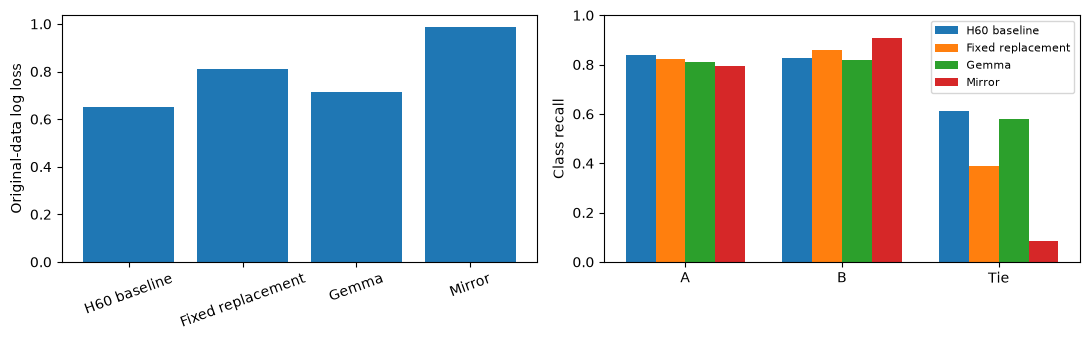

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_021'
r=json.loads((PUB/'futility_screen.json').read_text())
models={'H60 baseline':r['comparison']['baseline'],'Fixed replacement':r['comparison']['candidate'],**r['descriptive_experts']}
display(pd.DataFrame([{'model':name,'log_loss':m['log_loss'],'accuracy':m['accuracy'],'brier':m['brier']} for name,m in models.items()]))
print('Original rows/groups:',r['rows'],r['unique_prompt_groups'])
print('Loss reduction:',r['comparison']['loss_reduction'],'; paired group95:',r['comparison']['paired_group95'])
print('Decision:',r['decision'],'; original gate passed:',r['original_information_gate_passed'])
print('Later comparison complete:',r['later_comparison_complete'],'; official eligible:',r['official_submission_eligible'])
print('CPU elapsed seconds:',r['elapsed_cpu_seconds'],'; new GPU/inference/network:',r['new_gpu_executions'],r['new_inference_executions'],r['network_calls'])
fig,ax=plt.subplots(1,2,figsize=(11,3.5))
ax[0].bar(list(models),[m['log_loss'] for m in models.values()]);ax[0].tick_params(axis='x',rotation=20);ax[0].set_ylabel('Original-data log loss')
classes=['winner_model_a','winner_model_b','winner_tie'];x=np.arange(3)
for i,(name,m) in enumerate(models.items()):ax[1].bar(x+(i-1.5)*.19,[m['class_recall'][c] for c in classes],.19,label=name)
ax[1].set_xticks(x,['A','B','Tie']);ax[1].set_ylim(0,1);ax[1].set_ylabel('Class recall');ax[1].legend(fontsize=8)
fig.tight_layout();plt.show()

In [2]:
import hashlib
ROOT=Path.home()/'database/llm_classification_finetuning'
relative=next(iter(r['output_sha256']));path=ROOT/relative
assert hashlib.sha256(path.read_bytes()).hexdigest()==r['output_sha256'][relative]
a=np.load(path);y=a['labels'];non_tie=y<2;rows=[]
for key,name in [('baseline','H60 baseline'),('candidate','Fixed replacement'),('gemma','Gemma'),('mirror','Mirror')]:
 p=a[key].astype(float);mass=p[:,:2].sum(1);q=p[:,:2]/mass[:,None]
 binary=-np.log(np.maximum(np.where(y==2,p[:,2],mass),1e-15)).mean()
 conditional=-np.log(np.maximum(q[non_tie,y[non_tie]],1e-15)).mean()
 reconstructed=binary+non_tie.mean()*conditional
 assert abs(reconstructed-models[name]['log_loss'])<1e-12
 rows.append({'model':name,'tie_binary_loss':float(binary),'conditional_AB_loss':float(conditional),
  'conditional_AB_accuracy':float(np.mean(q[non_tie].argmax(1)==y[non_tie])),'reconstructed_total_loss':float(reconstructed)})
display(pd.DataFrame(rows))
print('Non-tie rows:',int(non_tie.sum()),'; true tie fraction:',float(np.mean(y==2)))
print('The mirror is weaker on both components here; higher raw B recall does not prove stronger conditional ranking.')
(PUB/'descriptive_decomposition.json').write_text(json.dumps({'posthoc_descriptive':True,'primary_decision_unchanged':True,
 'training_overlap':True,'independent_cv':False,'non_tie_rows':int(non_tie.sum()),'rows':rows},indent=2)+'\n')

,model,tie_binary_loss,conditional_AB_loss,conditional_AB_accuracy,reconstructed_total_loss
0,H60 baseline,0.465624,0.296081,0.879630,0.652988
1,Fixed replacement,0.559868,0.398851,0.867284,0.812266
2,Gemma,0.495263,0.343886,0.858025,0.712878
3,Mirror,0.685399,0.476631,0.851852,0.987017


Non-tie rows: 324 ; true tie fraction: 0.3671875
The mirror is weaker on both components here; higher raw B recall does not prove stronger conditional ranking.


1138